In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate
%matplotlib inline

In [ ]:
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.cluster import KMeans

## **DATA**

In [ ]:
path1 = '/content/gdrive/MyDrive/GAIAData/80-20/Tmin_2010_2014.xlsx'
train_data = pd.read_excel(path1)
train_data

,Date,Latitude,Longitude,IMD,NASA
0,2010-01-01,9.5,78.5,20.850000,22.31
1,2010-01-02,9.5,78.5,21.180000,22.76
2,2010-01-03,9.5,78.5,20.860001,22.12
3,2010-01-04,9.5,78.5,20.760000,21.48
4,2010-01-05,9.5,78.5,19.280001,19.58
...,...,...,...,...,...
20787,2014-12-27,12.5,80.5,20.155110,25.70
20788,2014-12-28,12.5,80.5,21.936960,25.54
20789,2014-12-29,12.5,80.5,22.427230,25.33
20790,2014-12-30,12.5,80.5,21.590350,25.47


In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20792 entries, 0 to 20791
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       20792 non-null  datetime64[ns]
 1   Latitude   20792 non-null  float64       
 2   Longitude  20792 non-null  float64       
 3   IMD        20792 non-null  float64       
 4   NASA       17872 non-null  float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 812.3 KB


In [ ]:
train_data['Month'] = pd.to_datetime(train_data['Date']).dt.month
train_data

,Date,Latitude,Longitude,IMD,NASA,Month
0,2010-01-01,9.5,78.5,20.850000,22.31,1
1,2010-01-02,9.5,78.5,21.180000,22.76,1
2,2010-01-03,9.5,78.5,20.860001,22.12,1
3,2010-01-04,9.5,78.5,20.760000,21.48,1
4,2010-01-05,9.5,78.5,19.280001,19.58,1
...,...,...,...,...,...,...
20787,2014-12-27,12.5,80.5,20.155110,25.70,12
20788,2014-12-28,12.5,80.5,21.936960,25.54,12
20789,2014-12-29,12.5,80.5,22.427230,25.33,12
20790,2014-12-30,12.5,80.5,21.590350,25.47,12


## **DATA PREP**

In [ ]:
season_mapping = {
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Pre-Summer',
    4: 'Pre-Summer',
    5: 'Summer',
    6: 'Summer',
    7: 'Southwest Monsoon',
    8: 'Southwest Monsoon',
    9: 'Autumn',
    10: 'Autumn',
    11: 'Northeast Monsoon'
}

In [ ]:
train_data['season'] = train_data['Month'].map(season_mapping)
train_data

,Date,Latitude,Longitude,IMD,NASA,Month,season
0,2010-01-01,9.5,78.5,20.850000,22.31,1,Winter
1,2010-01-02,9.5,78.5,21.180000,22.76,1,Winter
2,2010-01-03,9.5,78.5,20.860001,22.12,1,Winter
3,2010-01-04,9.5,78.5,20.760000,21.48,1,Winter
4,2010-01-05,9.5,78.5,19.280001,19.58,1,Winter
...,...,...,...,...,...,...,...
20787,2014-12-27,12.5,80.5,20.155110,25.70,12,Winter
20788,2014-12-28,12.5,80.5,21.936960,25.54,12,Winter
20789,2014-12-29,12.5,80.5,22.427230,25.33,12,Winter
20790,2014-12-30,12.5,80.5,21.590350,25.47,12,Winter


In [ ]:
one_hot_encoded = pd.get_dummies(train_data['season'])

In [ ]:
train_encoded = pd.concat([train_data, one_hot_encoded], axis=1)
train_encoded

,Date,Latitude,Longitude,IMD,NASA,Month,season,Autumn,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter
0,2010-01-01,9.5,78.5,20.850000,22.31,1,Winter,False,False,False,False,False,True
1,2010-01-02,9.5,78.5,21.180000,22.76,1,Winter,False,False,False,False,False,True
2,2010-01-03,9.5,78.5,20.860001,22.12,1,Winter,False,False,False,False,False,True
3,2010-01-04,9.5,78.5,20.760000,21.48,1,Winter,False,False,False,False,False,True
4,2010-01-05,9.5,78.5,19.280001,19.58,1,Winter,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20787,2014-12-27,12.5,80.5,20.155110,25.70,12,Winter,False,False,False,False,False,True
20788,2014-12-28,12.5,80.5,21.936960,25.54,12,Winter,False,False,False,False,False,True
20789,2014-12-29,12.5,80.5,22.427230,25.33,12,Winter,False,False,False,False,False,True
20790,2014-12-30,12.5,80.5,21.590350,25.47,12,Winter,False,False,False,False,False,True


# **ALTITUDE WITH LAT AND LON**

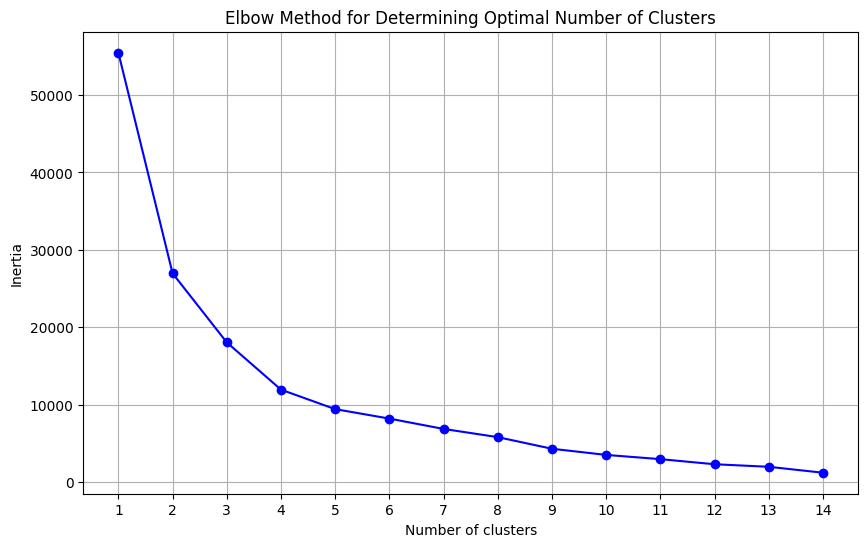

In [ ]:
coordinates = train_encoded[['Latitude', 'Longitude']]

cluster_range = range(1, 15)

# Initialize list to store the inertias (within-cluster sum of squares)
inertias = []

# Calculate the inertia for each number of clusters
for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(coordinates)
    inertias.append(kmeans.inertia_)

# Plot the elbow graph
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, inertias, '-o', color='blue')
plt.title('Elbow Method for Determining Optimal Number of Clusters')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

lowest_k = inertias.index(min(inertias)) + 1

In [ ]:
# Function to apply KMeans clustering
def apply_kmeans(X, n_clusters):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    clusters = kmeans.fit_predict(X[['Latitude', 'Longitude']])
    X_new = X.copy()
    X_new['Cluster'] = clusters
    return pd.get_dummies(X_new, columns=['Cluster'])

In [ ]:
data_after_kmeans = apply_kmeans(train_encoded, n_clusters = lowest_k)
data_after_kmeans

,Date,Latitude,Longitude,IMD,NASA,Month,season,Autumn,Northeast Monsoon,Pre-Summer,...,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9,Cluster_10,Cluster_11,Cluster_12,Cluster_13
0,2010-01-01,9.5,78.5,20.850000,22.31,1,Winter,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,2010-01-02,9.5,78.5,21.180000,22.76,1,Winter,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,2010-01-03,9.5,78.5,20.860001,22.12,1,Winter,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,2010-01-04,9.5,78.5,20.760000,21.48,1,Winter,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,2010-01-05,9.5,78.5,19.280001,19.58,1,Winter,False,False,False,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20787,2014-12-27,12.5,80.5,20.155110,25.70,12,Winter,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20788,2014-12-28,12.5,80.5,21.936960,25.54,12,Winter,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20789,2014-12-29,12.5,80.5,22.427230,25.33,12,Winter,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20790,2014-12-30,12.5,80.5,21.590350,25.47,12,Winter,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# prompt: count the number nan values and remove them

nan_count = data_after_kmeans.isnull().sum().sum()
print(f"Number of NaN values: {nan_count}")

data_after_kmeans = data_after_kmeans.dropna()

Number of NaN values: 2920


## **TRAIN_TEST DATA**

In [ ]:
data_after_kmeans = data_after_kmeans.drop(['Month', 'season','Autumn', 'Date', 'Latitude', 'Longitude'], axis = 1)
data_after_kmeans

,IMD,NASA,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter,Cluster_0,Cluster_1,Cluster_2,...,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9,Cluster_10,Cluster_11,Cluster_12,Cluster_13
0,20.850000,22.31,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,21.180000,22.76,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,20.860001,22.12,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,20.760000,21.48,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,19.280001,19.58,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20787,20.155110,25.70,False,False,False,False,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
20788,21.936960,25.54,False,False,False,False,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
20789,22.427230,25.33,False,False,False,False,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False
20790,21.590350,25.47,False,False,False,False,True,True,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
y = data_after_kmeans['IMD']
X = data_after_kmeans.drop(['IMD'], axis = 1)

X

,NASA,Northeast Monsoon,Pre-Summer,Southwest Monsoon,Summer,Winter,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Cluster_5,Cluster_6,Cluster_7,Cluster_8,Cluster_9,Cluster_10,Cluster_11,Cluster_12,Cluster_13
0,22.31,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,22.76,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,22.12,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False
3,21.48,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False
4,19.58,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20787,25.70,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False
20788,25.54,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False
20789,25.33,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False
20790,25.47,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
X_train, X_test, Y_train,Y_test = train_test_split(X, y, train_size = 0.8, shuffle =  True, random_state = 99)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)


## **Linear Regression**

In [ ]:
model = LinearRegression()
model.fit(X_train, Y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, y_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, y_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, y_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, y_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, y_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, y_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.0666333336122833
Training MAE:  0.7615377999855674
Training R2:  0.8341783943564884


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.0083242741436866
Training MAE:  0.7580019552404017
Test R2:  0.8357913352186519


In [ ]:
result1 = []
result1.append('Linear Regression')
result1.append(metrics.mean_squared_error(Y_train, y_train_pred))
result1.append(metrics.mean_absolute_error(Y_train, y_train_pred))
result1.append(metrics.r2_score(Y_train, y_train_pred))
result1.append(metrics.mean_squared_error(Y_test, y_test_pred))
result1.append(metrics.mean_absolute_error(Y_test, y_test_pred))
result1.append(metrics.r2_score(Y_test, y_test_pred))

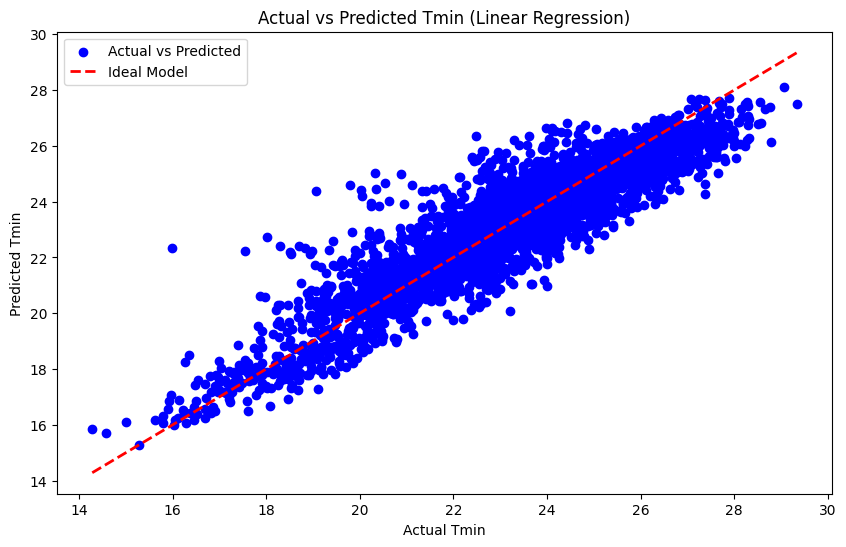

In [ ]:
# prompt: plot

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, y_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'k--', lw=2, color='red', label='Ideal Model')
plt.xlabel('Actual Tmin')
plt.ylabel('Predicted Tmin')
plt.title('Actual vs Predicted Tmin (Linear Regression)')
plt.legend()
plt.show()


In [ ]:
print("Linear Regression Coefficients:")
print(model.coef_)

Linear Regression Coefficients:
[ 1.34616574 -0.23421811 -0.05141159  0.16113903  0.31387282 -0.72798061
 -0.08397051  0.03875069 -0.26448843  0.35352873  0.04865641 -0.02968575
 -0.40095034  0.34398855  0.46847007  0.37920599 -0.55857312  0.30004259
 -0.06775116 -0.68498653]


In [ ]:
print(model.intercept_)

23.150824801415624


In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted Tmin = {model.intercept_:.2f}"
for i, coef in enumerate(model.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted Tmin = 23.15 + 1.35 * NASA + -0.23 * Northeast Monsoon + -0.05 * Pre-Summer + 0.16 * Southwest Monsoon + 0.31 * Summer + -0.73 * Winter + -0.08 * Cluster_0 + 0.04 * Cluster_1 + -0.26 * Cluster_2 + 0.35 * Cluster_3 + 0.05 * Cluster_4 + -0.03 * Cluster_5 + -0.40 * Cluster_6 + 0.34 * Cluster_7 + 0.47 * Cluster_8 + 0.38 * Cluster_9 + -0.56 * Cluster_10 + 0.30 * Cluster_11 + -0.07 * Cluster_12 + -0.68 * Cluster_13


## **LINEAR REGRESSION - RIDGE**


In [ ]:
ridge_model = Ridge(alpha=0.5)
ridge_model.fit(X_train, Y_train)

ridge_y_train_pred = ridge_model.predict(X_train)
ridge_y_test_pred = ridge_model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, ridge_y_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, ridge_y_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, ridge_y_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, ridge_y_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, ridge_y_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, ridge_y_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.066633342458898
Training MAE:  0.7615459981044462
Training R2:  0.8341783929811706


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.0083269835947593
Training MAE:  0.7580091933080791
Test R2:  0.835790893976331


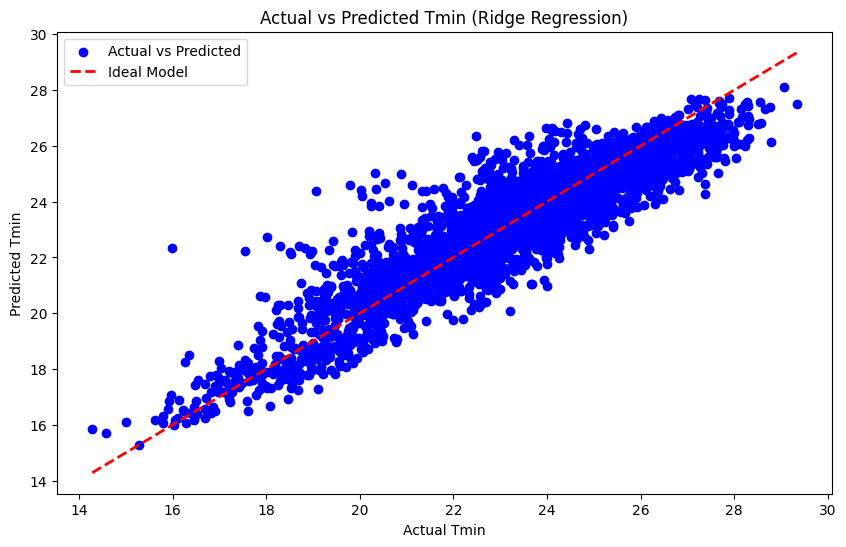

In [ ]:
# prompt: plot

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, ridge_y_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'k--', lw=2, color='red', label='Ideal Model')
plt.xlabel('Actual Tmin')
plt.ylabel('Predicted Tmin')
plt.title('Actual vs Predicted Tmin (Ridge Regression)')
plt.legend()
plt.show()


In [ ]:
print("Ridge Regression (a = 0.5) Coefficients:")
print(ridge_model.coef_)

Ridge Regression (a = 0.5) Coefficients:
[ 1.34601334 -0.23421286 -0.05137552  0.16115802  0.31391217 -0.72799378
 -0.08393617  0.03879223 -0.26452054  0.35351176  0.04863839 -0.02964739
 -0.40089927  0.34396063  0.46844776  0.37915372 -0.55858924  0.30004413
 -0.06773486 -0.68496177]


In [ ]:
ridge_model.intercept_

23.150824801415624

In [ ]:
# prompt: create an equation with the coeff aanf intercept

equation = f"Predicted Tmin = {ridge_model.intercept_:.2f}"
for i, coef in enumerate(ridge_model.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")


Equation: Predicted Tmin = 23.15 + 1.35 * NASA + -0.23 * Northeast Monsoon + -0.05 * Pre-Summer + 0.16 * Southwest Monsoon + 0.31 * Summer + -0.73 * Winter + -0.08 * Cluster_0 + 0.04 * Cluster_1 + -0.26 * Cluster_2 + 0.35 * Cluster_3 + 0.05 * Cluster_4 + -0.03 * Cluster_5 + -0.40 * Cluster_6 + 0.34 * Cluster_7 + 0.47 * Cluster_8 + 0.38 * Cluster_9 + -0.56 * Cluster_10 + 0.30 * Cluster_11 + -0.07 * Cluster_12 + -0.68 * Cluster_13


In [ ]:
ridge_model_2 = Ridge()
ridge_model_2.fit(X_train, Y_train)

ridge_y_train_pred_2 = ridge_model_2.predict(X_train)
ridge_y_test_pred_2 = ridge_model_2.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, ridge_y_train_pred_2))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, ridge_y_train_pred_2))
print("Training R2: ", metrics.r2_score(Y_train, ridge_y_train_pred_2))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, ridge_y_test_pred_2))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, ridge_y_test_pred_2))
print("Test R2: ", metrics.r2_score(Y_test, ridge_y_test_pred_2))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.066633368987441
Training MAE:  0.7615541925490322
Training R2:  0.8341783888569739


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.0083297078995572
Training MAE:  0.758016626954896
Test R2:  0.835790450315036


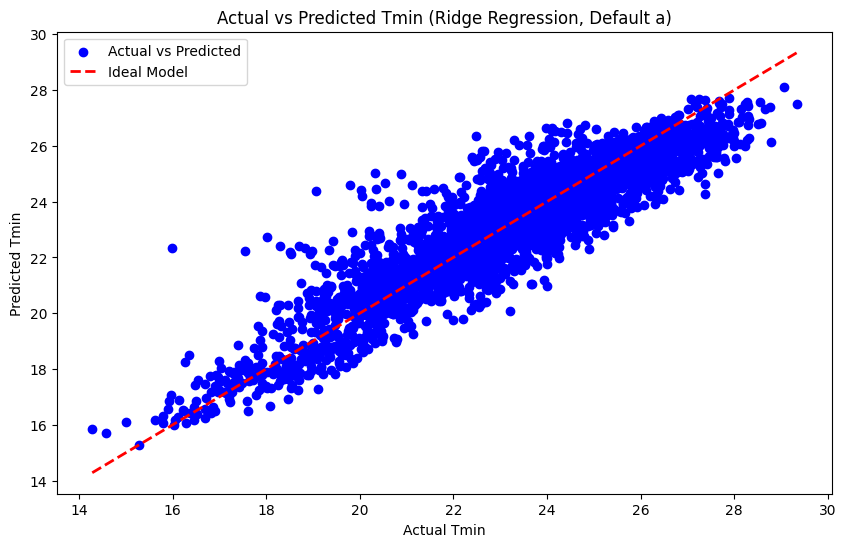

In [ ]:
# prompt: plot

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, ridge_y_test_pred_2, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'k--', lw=2, color='red', label='Ideal Model')
plt.xlabel('Actual Tmin')
plt.ylabel('Predicted Tmin')
plt.title('Actual vs Predicted Tmin (Ridge Regression, Default a)')
plt.legend()
plt.show()


In [ ]:
print("Ridge Regression (a = 1) Coefficients:")
print(ridge_model_2.coef_)

Ridge Regression (a = 1) Coefficients:
[ 1.345861   -0.23420761 -0.05133947  0.161177    0.31395149 -0.72800693
 -0.08390184  0.03883374 -0.26455263  0.3534948   0.04862036 -0.02960904
 -0.40084822  0.34393273  0.46842545  0.37910147 -0.55860534  0.30004567
 -0.06771856 -0.684937  ]


In [ ]:
ridge_model_2.intercept_

23.150824801415624

In [ ]:
equation = f"Predicted Tmin = {ridge_model_2.intercept_:.2f}"
for i, coef in enumerate(ridge_model_2.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")

Equation: Predicted Tmin = 23.15 + 1.35 * NASA + -0.23 * Northeast Monsoon + -0.05 * Pre-Summer + 0.16 * Southwest Monsoon + 0.31 * Summer + -0.73 * Winter + -0.08 * Cluster_0 + 0.04 * Cluster_1 + -0.26 * Cluster_2 + 0.35 * Cluster_3 + 0.05 * Cluster_4 + -0.03 * Cluster_5 + -0.40 * Cluster_6 + 0.34 * Cluster_7 + 0.47 * Cluster_8 + 0.38 * Cluster_9 + -0.56 * Cluster_10 + 0.30 * Cluster_11 + -0.07 * Cluster_12 + -0.68 * Cluster_13


In [ ]:
ridge_model_3 = Ridge(alpha=0.0001)
ridge_model_3.fit(X_train, Y_train)

ridge_y_train_pred_3 = ridge_model_3.predict(X_train)
ridge_y_test_pred_3 = ridge_model_3.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, ridge_y_train_pred_3))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, ridge_y_train_pred_3))
print("Training R2: ", metrics.r2_score(Y_train, ridge_y_train_pred_3))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, ridge_y_test_pred_3))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, ridge_y_test_pred_3))
print("Test R2: ", metrics.r2_score(Y_test, ridge_y_test_pred_3))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.0666333336122837
Training MAE:  0.7615378016255582
Training R2:  0.8341783943564883


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.0083242746840906
Training MAE:  0.7580019566883914
Test R2:  0.8357913351306454


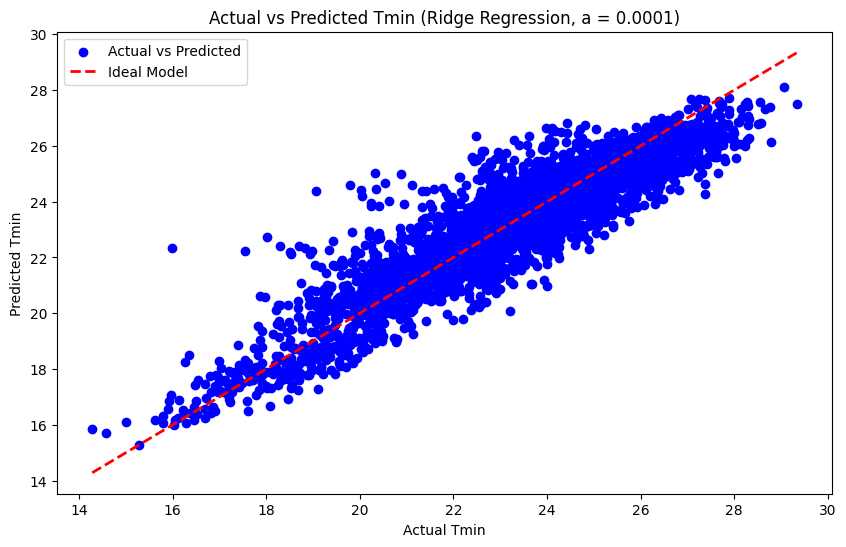

In [ ]:
# prompt: plot

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, ridge_y_test_pred_3, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'k--', lw=2, color='red', label='Ideal Model')
plt.xlabel('Actual Tmin')
plt.ylabel('Predicted Tmin')
plt.title('Actual vs Predicted Tmin (Ridge Regression, a = 0.0001)')
plt.legend()
plt.show()


In [ ]:
print("Ridge Regression (a = 0.0001) Coefficients:")
print(ridge_model_3.coef_)

Ridge Regression (a = 0.0001) Coefficients:
[ 1.34616571 -0.23421811 -0.05141158  0.16113903  0.31387283 -0.72798061
 -0.08397049  0.03875072 -0.26448842  0.35352874  0.04865643 -0.02968573
 -0.40095031  0.34398856  0.46847008  0.379206   -0.55857311  0.3000426
 -0.06775114 -0.68498652]


In [ ]:
ridge_model_3.intercept_

23.150824801415624

In [ ]:
equation = f"Predicted Tmin = {ridge_model_3.intercept_:.2f}"
for i, coef in enumerate(ridge_model_3.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")

Equation: Predicted Tmin = 23.15 + 1.35 * NASA + -0.23 * Northeast Monsoon + -0.05 * Pre-Summer + 0.16 * Southwest Monsoon + 0.31 * Summer + -0.73 * Winter + -0.08 * Cluster_0 + 0.04 * Cluster_1 + -0.26 * Cluster_2 + 0.35 * Cluster_3 + 0.05 * Cluster_4 + -0.03 * Cluster_5 + -0.40 * Cluster_6 + 0.34 * Cluster_7 + 0.47 * Cluster_8 + 0.38 * Cluster_9 + -0.56 * Cluster_10 + 0.30 * Cluster_11 + -0.07 * Cluster_12 + -0.68 * Cluster_13


In [ ]:
result2 = []
result2.append('Linear Regression - Ridge (Alpha = 0.5)')
result2.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred))
result2.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred))
result2.append(metrics.r2_score(Y_train, ridge_y_train_pred))
result2.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred))
result2.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred))
result2.append(metrics.r2_score(Y_test, ridge_y_test_pred))

result3 = []
result3.append('Linear Regression - Ridge (Alpha = 1)')
result3.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred_2))
result3.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred_2))
result3.append(metrics.r2_score(Y_train, ridge_y_train_pred_2))
result3.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred_2))
result3.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred_2))
result3.append(metrics.r2_score(Y_test, ridge_y_test_pred_2))

result4 = []
result4.append('Linear Regression - Ridge (Alpha = 0.0001)')
result4.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred_3))
result4.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred_3))
result4.append(metrics.r2_score(Y_train, ridge_y_train_pred_3))
result4.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred_3))
result4.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred_3))
result4.append(metrics.r2_score(Y_test, ridge_y_test_pred_3))

# **LINEAR REGRESSION - LASSO**

In [ ]:
lasso_model = Lasso()
lasso_model.fit(X_train, Y_train)

lasso_y_train_pred = lasso_model.predict(X_train)
lasso_y_test_pred = lasso_model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, lasso_y_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, lasso_y_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, lasso_y_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, lasso_y_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, lasso_y_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, lasso_y_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  4.525016022674267
Training MAE:  1.7434629042762357
Training R2:  0.2965291831811333


VALIDATION RESULTS
-------------------------------------
Test MSE:  4.280529213623445
Training MAE:  1.6902077845496448
Test R2:  0.3029028411285709


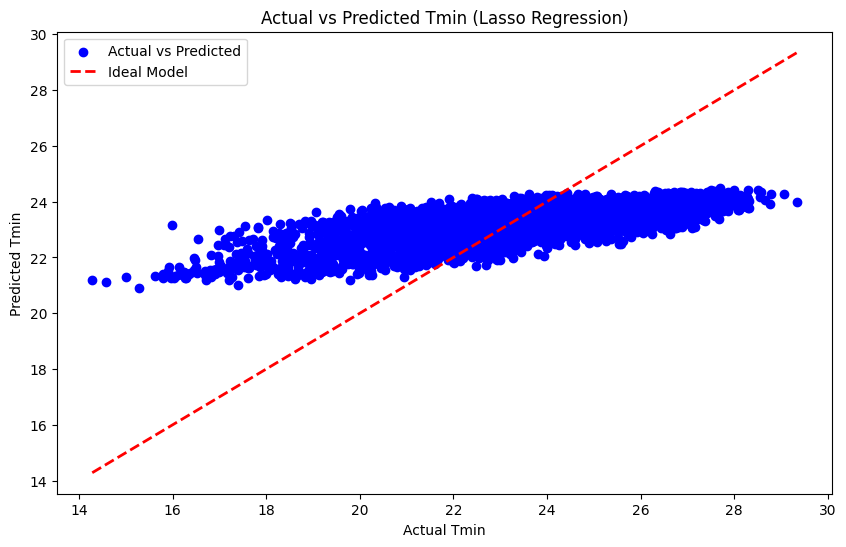

In [ ]:
# prompt: plot

plt.figure(figsize=(10, 6))
plt.scatter(Y_test, lasso_y_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'k--', lw=2, color='red', label='Ideal Model')
plt.xlabel('Actual Tmin')
plt.ylabel('Predicted Tmin')
plt.title('Actual vs Predicted Tmin (Lasso Regression)')
plt.legend()
plt.show()


In [ ]:
print("Lasso Regression Coefficients:")
print(lasso_model.coef_)

Lasso Regression Coefficients:
[ 0.6231098  -0.          0.          0.          0.         -0.10392205
  0.          0.         -0.          0.         -0.          0.
 -0.          0.          0.          0.         -0.          0.
 -0.         -0.        ]


In [ ]:
equation = f"Predicted Tmin = {lasso_model.intercept_:.2f}"
for i, coef in enumerate(lasso_model.coef_):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")

Equation: Predicted Tmin = 23.15 + 0.62 * NASA + -0.10 * Winter


In [ ]:
result5 = []
result5.append('Linear Regression - LASSO')
result5.append(metrics.mean_squared_error(Y_train, ridge_y_train_pred))
result5.append(metrics.mean_absolute_error(Y_train, ridge_y_train_pred))
result5.append(metrics.r2_score(Y_train, ridge_y_train_pred))
result5.append(metrics.mean_squared_error(Y_test, ridge_y_test_pred))
result5.append(metrics.mean_absolute_error(Y_test, ridge_y_test_pred))
result5.append(metrics.r2_score(Y_test, ridge_y_test_pred))

# **SUPPORT VECTOR MACHINE**

In [ ]:
svm_model = SVR(kernel='linear', C=1.0)
svm_model.fit(X_train, Y_train)

svm_train_pred = svm_model.predict(X_train)
svm_test_pred = svm_model.predict(X_test)

In [ ]:
print("TRAIN RESULTS\n---------------------------------------")
print("Training MSE: ", metrics.mean_squared_error(Y_train, svm_train_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_train, svm_train_pred))
print("Training R2: ", metrics.r2_score(Y_train, svm_train_pred))
print('\n')
print("VALIDATION RESULTS\n-------------------------------------")
print("Test MSE: ", metrics.mean_squared_error(Y_test, svm_test_pred))
print("Training MAE: ", metrics.mean_absolute_error(Y_test, svm_test_pred))
print("Test R2: ", metrics.r2_score(Y_test, svm_test_pred))

TRAIN RESULTS
---------------------------------------
Training MSE:  1.1841187835428781
Training MAE:  0.7356320487074887
Training R2:  0.8159137992671293


VALIDATION RESULTS
-------------------------------------
Test MSE:  1.073714277466333
Training MAE:  0.7227989101477748
Test R2:  0.8251423749476334


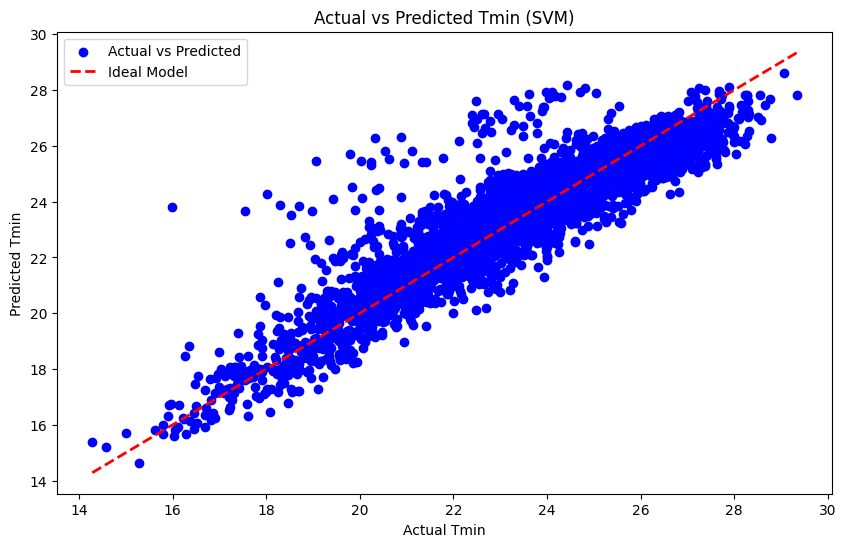

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, svm_test_pred, color='blue', label='Actual vs Predicted')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'k--', lw=2, color='red', label='Ideal Model')
plt.xlabel('Actual Tmin')
plt.ylabel('Predicted Tmin')
plt.title('Actual vs Predicted Tmin (SVM)')
plt.legend()
plt.show()

In [ ]:
print("SVM Coefficients:")
print(svm_model.coef_)

SVM Coefficients:
[[ 1.74186151 -0.18061963 -0.10781852  0.11818291  0.21623501 -0.55976076
  -0.15538492 -0.08011882 -0.18669999  0.34678613  0.29878114 -0.1078578
  -0.51472611  0.38887258  0.46814931  0.40139686 -0.50547081  0.25116641
  -0.11744597 -0.71578287]]


In [ ]:
svm_model.intercept_

array([23.27063064])

In [ ]:
equation = f"Predicted Tmin = {svm_model.intercept_[0]:.2f}"
for i, coef in enumerate(svm_model.coef_[0]):
    if coef != 0:
        equation += f" + {coef:.2f} * {X.columns[i]}"

print(f"Equation: {equation}")

Equation: Predicted Tmin = 23.27 + 1.74 * NASA + -0.18 * Northeast Monsoon + -0.11 * Pre-Summer + 0.12 * Southwest Monsoon + 0.22 * Summer + -0.56 * Winter + -0.16 * Cluster_0 + -0.08 * Cluster_1 + -0.19 * Cluster_2 + 0.35 * Cluster_3 + 0.30 * Cluster_4 + -0.11 * Cluster_5 + -0.51 * Cluster_6 + 0.39 * Cluster_7 + 0.47 * Cluster_8 + 0.40 * Cluster_9 + -0.51 * Cluster_10 + 0.25 * Cluster_11 + -0.12 * Cluster_12 + -0.72 * Cluster_13


In [ ]:
result6 = []
result6.append('Support Vector - SVM')
result6.append(metrics.mean_squared_error(Y_train, svm_train_pred))
result6.append(metrics.mean_absolute_error(Y_train, svm_train_pred))
result6.append(metrics.r2_score(Y_train, svm_train_pred))
result6.append(metrics.mean_squared_error(Y_test, svm_test_pred))
result6.append(metrics.mean_absolute_error(Y_test, svm_test_pred))
result6.append(metrics.r2_score(Y_test, svm_test_pred))

# **RESULTS**

In [ ]:
print(tabulate([result1,result2,result3,result4,result5,result6], headers=['METHOD', 'TRAIN MSE', 'TRAIN MAE', 'TRAIN R_SQUARED', 'TEST MSE', 'TEST MAE','TEST R-SQUARED']))

METHOD                                        TRAIN MSE    TRAIN MAE    TRAIN R_SQUARED    TEST MSE    TEST MAE    TEST R-SQUARED
------------------------------------------  -----------  -----------  -----------------  ----------  ----------  ----------------
Linear Regression                               1.06663     0.761538           0.834178     1.00832    0.758002          0.835791
Linear Regression - Ridge (Alpha = 0.5)         1.06663     0.761546           0.834178     1.00833    0.758009          0.835791
Linear Regression - Ridge (Alpha = 1)           1.06663     0.761554           0.834178     1.00833    0.758017          0.83579
Linear Regression - Ridge (Alpha = 0.0001)      1.06663     0.761538           0.834178     1.00832    0.758002          0.835791
Linear Regression - LASSO                       1.06663     0.761546           0.834178     1.00833    0.758009          0.835791
Support Vector - SVM                            1.18412     0.735632           0.815914    

# **GEOPY DISTANCE**

In [ ]:
from geopy.distance import geodesic

# Define two locations as (latitude, longitude) tuples
location1 = (8.5, 78.5)
location2 = (9.5, 78.5)

# Calculate the distance between the two points
distance = geodesic(location1, location2).kilometers

print(f"Distance: {distance} kilometers")

Distance: 110.60148016366607 kilometers
